# Ticket Priority Prediction with Explainable ML
## Notebook 1: Data loading, quality checks, EDA and splits
Put `aa_dataset-tickets-multi-lang-5-2-50-version.csv` in the same folder as this notebook (unzip archive.zip).

In [5]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\mailt\OneDrive\Documents\ticket-priority-project
['.git', '.ipynb_checkpoints', '01_data_prep_and_baseline.ipynb', 'aa_dataset-tickets-multi-lang-5-2-50-version.csv', 'archive']


In [6]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
FILE = 'aa_dataset-tickets-multi-lang-5-2-50-version.csv'
df = pd.read_csv(FILE)
print(df.shape)
df.head()

(28587, 16)


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte eine...",Vielen Dank für die Meldung des kritischen Sic...,Incident,Technical Support,high,de,51,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Thank you for reaching out, <name>. We are awa...",Incident,Technical Support,high,en,51,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your inquiry. Our products suppo...,Request,Returns and Exchanges,medium,en,51,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",We appreciate you reaching out with your billi...,Request,Billing and Payments,low,en,51,Billing,Payment,Account,Documentation,Feedback,NaN,NaN,NaN
4,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Thank you for your inquiry. Our product suppor...,Problem,Sales and Pre-Sales,medium,en,51,Product,Feature,Feedback,Tech Support,NaN,NaN,NaN,NaN


## 1. Data quality: nulls (report this at the supervision meeting)

In [7]:
nulls = pd.DataFrame({'nulls': df.isna().sum(), 'pct': (df.isna().mean()*100).round(2)})
nulls

,nulls,pct
subject,3838,13.43
body,0,0.00
answer,7,0.02
type,0,0.00
queue,0,0.00
priority,0,0.00
language,0,0.00
version,0,0.00
tag_1,0,0.00
tag_2,13,0.05


## 2. Filter to English only (agreed with supervisor)

In [8]:
print(df['language'].value_counts())
en = df[df['language'] == 'en'].copy().reset_index(drop=True)
print('English rows:', len(en))
print('Null body:', en['body'].isna().sum(), '| Null subject:', en['subject'].isna().sum())
print('Duplicate tickets:', en.duplicated(['subject','body']).sum())

language
en    16338
de    12249
Name: count, dtype: int64
English rows: 16338
Null body: 0 | Null subject: 2607
Duplicate tickets: 0


## 3. Target variable and class balance

priority
medium    6618
high      6346
low       3374
Name: count, dtype: int64
priority
medium    40.5
high      38.8
low       20.7
Name: count, dtype: float64


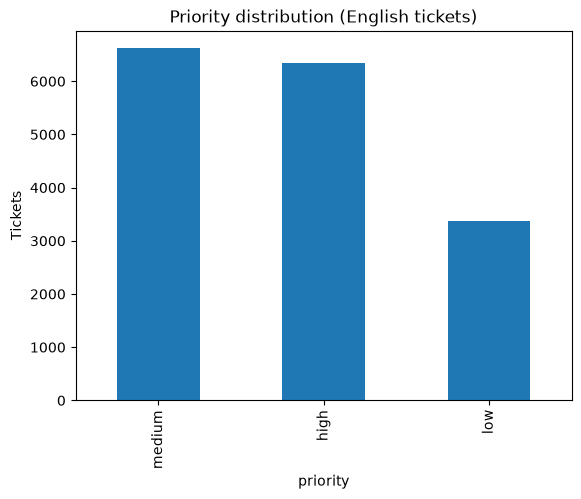

In [9]:
counts = en['priority'].value_counts()
print(counts); print((counts/len(en)*100).round(1))
counts.plot(kind='bar', title='Priority distribution (English tickets)')
plt.ylabel('Tickets'); plt.show()

## 4. Build the text input (subject + body)

In [10]:
en['subject'] = en['subject'].fillna('')
en['text'] = (en['subject'] + ' ' + en['body']).str.strip()

def clean(t):
    t = t.lower()
    t = re.sub(r'<[^>]+>', ' ', t)          # html tags
    t = re.sub(r'[^a-z0-9\s]', ' ', t)      # punctuation
    return re.sub(r'\s+', ' ', t).strip()

en['text_clean'] = en['text'].apply(clean)
en['n_words'] = en['text_clean'].str.split().str.len()
en['n_words'].describe()

count    16338.000000
mean        59.291590
std         27.278779
min          2.000000
25%         36.000000
50%         61.000000
75%         83.000000
max        178.000000
Name: n_words, dtype: float64

## 5. Quick EDA

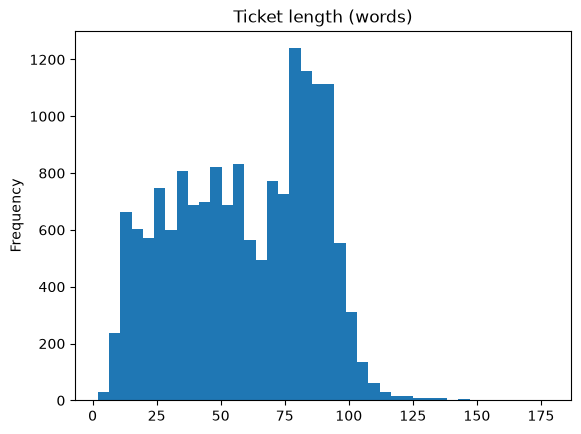

priority                         high   low  medium
queue                                              
Billing and Payments             0.30  0.21    0.48
Customer Service                 0.19  0.35    0.47
General Inquiry                  0.16  0.55    0.29
Human Resources                  0.10  0.49    0.41
IT Support                       0.48  0.09    0.43
Product Support                  0.29  0.19    0.51
Returns and Exchanges            0.23  0.38    0.39
Sales and Pre-Sales              0.17  0.37    0.46
Service Outages and Maintenance  0.70  0.12    0.17
Technical Support                0.58  0.11    0.30
priority  high   low  medium
type                        
Change    0.40  0.20    0.40
Incident  0.43  0.19    0.38
Problem   0.38  0.21    0.41
Request   0.33  0.23    0.44


In [11]:
en['n_words'].plot(kind='hist', bins=40, title='Ticket length (words)'); plt.show()
print(pd.crosstab(en['queue'], en['priority'], normalize='index').round(2))
print(pd.crosstab(en['type'], en['priority'], normalize='index').round(2))

In [12]:
from sklearn.feature_extraction.text import CountVectorizer
for p in ['high','medium','low']:
    cv = CountVectorizer(stop_words='english', max_features=15)
    cv.fit(en.loc[en.priority==p,'text_clean'])
    print(p, '->', list(cv.vocabulary_.keys()))

high -> ['customer', 'support', 'problem', 'issue', 'provide', 'assistance', 'information', 'appreciate', 'analytics', 'data', 'investment', 'security', 'software', 'medical', 'digital']
medium -> ['integration', 'customer', 'support', 'information', 'provide', 'software', 'analytics', 'appreciate', 'issue', 'problem', 'assistance', 'data', 'digital', 'security', 'medical']
low -> ['customer', 'support', 'provide', 'assistance', 'problem', 'issue', 'information', 'security', 'investment', 'data', 'software', 'integration', 'appreciate', 'medical', 'analytics']


## 6. Train / validation / test split (70 / 15 / 15, stratified)
- **Train**: fit the models
- **Validation**: tune hyperparameters and compare models
- **Test**: used once at the end for an unbiased final estimate

In [23]:
X = en['text_clean']; y = en['priority']
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
for n, s in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(n, len(s), (s.value_counts(normalize=True)*100).round(1).to_dict())

train 11436 {'medium': 40.5, 'high': 38.8, 'low': 20.7}
val 2451 {'medium': 40.5, 'high': 38.8, 'low': 20.6}
test 2451 {'medium': 40.5, 'high': 38.8, 'low': 20.6}


In [28]:
en.to_csv('tickets_en_clean.csv', index=False)
pd.DataFrame({'text_clean': X_train, 'priority': y_train}).to_csv('train.csv', index=False)
pd.DataFrame({'text_clean': X_val, 'priority': y_val}).to_csv('val.csv', index=False)
pd.DataFrame({'text_clean': X_test, 'priority': y_test}).to_csv('test.csv', index=False)

## 7. First baseline: TF-IDF + Logistic Regression (validation set only)

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, confusion_matrix

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2), stop_words='english', min_df=2)
A_train = tfidf.fit_transform(X_train); A_val = tfidf.transform(X_val)
lr = LogisticRegression(max_iter=1000, class_weight='balanced').fit(A_train, y_train)
pred = lr.predict(A_val)
print(classification_report(y_val, pred))
print('Macro F1:', round(f1_score(y_val, pred, average='macro'), 3))
print(confusion_matrix(y_val, pred, labels=['low','medium','high']))

              precision    recall  f1-score   support

        high       0.68      0.65      0.66       952
         low       0.52      0.61      0.56       506
      medium       0.63      0.60      0.62       993

    accuracy                           0.62      2451
   macro avg       0.61      0.62      0.61      2451
weighted avg       0.63      0.62      0.62      2451

Macro F1: 0.615
[[311 121  74]
 [173 598 222]
 [111 224 617]]
